## Deep Learning

**Importing Necessary Libraries**

In [16]:
import math
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import LSTM
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split



In [17]:
import pandas as pd

df = pd.read_csv(
    "Tesla.csv.csv",
    parse_dates=["Date"],
    index_col="Date"
)
df.head()

,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2010-06-29,19.000000,25.00,17.540001,23.889999,18766300,23.889999
2010-06-30,25.790001,30.42,23.299999,23.830000,17187100,23.830000
2010-07-01,25.000000,25.92,20.270000,21.959999,8218800,21.959999
2010-07-02,23.000000,23.10,18.709999,19.200001,5139800,19.200001
2010-07-06,20.000000,20.00,15.830000,16.110001,6866900,16.110001


Reading The Data

In [18]:
from google.colab import files

uploaded = files.upload()

Saving Tesla.csv.csv to Tesla.csv (1).csv


In [19]:
df.describe()

,Open,High,Low,Close,Volume,Adj Close
count,1692.000000,1692.000000,1692.000000,1692.000000,1.692000e+03,1692.000000
mean,132.441572,134.769698,129.996223,132.428658,4.270741e+06,132.428658
std,94.309923,95.694914,92.855227,94.313187,4.295971e+06,94.313187
min,16.139999,16.629999,14.980000,15.800000,1.185000e+05,15.800000
25%,30.000000,30.650000,29.215000,29.884999,1.194350e+06,29.884999
50%,156.334999,162.370002,153.150002,158.160004,3.180700e+06,158.160004
75%,220.557495,224.099999,217.119999,220.022503,5.662100e+06,220.022503
max,287.670013,291.420013,280.399994,286.040009,3.716390e+07,286.040009


In [52]:
print(df.shape)
df.info()

(1692, 6)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1692 entries, 2010-06-29 to 2017-03-17
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Open       1692 non-null   float64
 1   High       1692 non-null   float64
 2   Low        1692 non-null   float64
 3   Close      1692 non-null   float64
 4   Volume     1692 non-null   int64  
 5   Adj Close  1692 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 92.5 KB


**Data Visualization**

<Axes: >

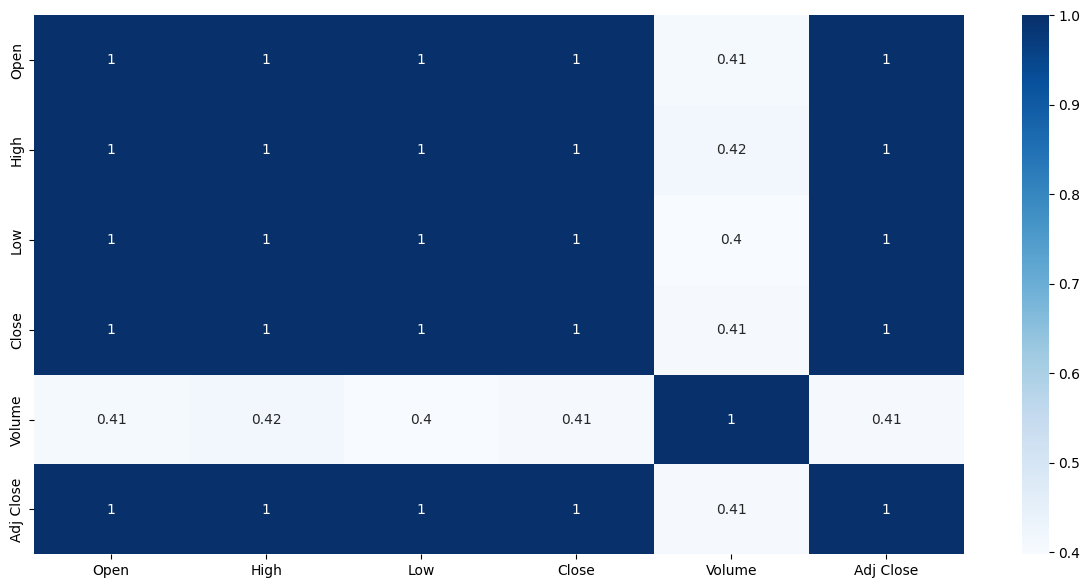

In [21]:
plt.figure(figsize=(15,7))
sns.heatmap(df.corr(),cbar=True,annot=True,cmap="Blues")

Text(0, 0.5, 'Closed Price USD')

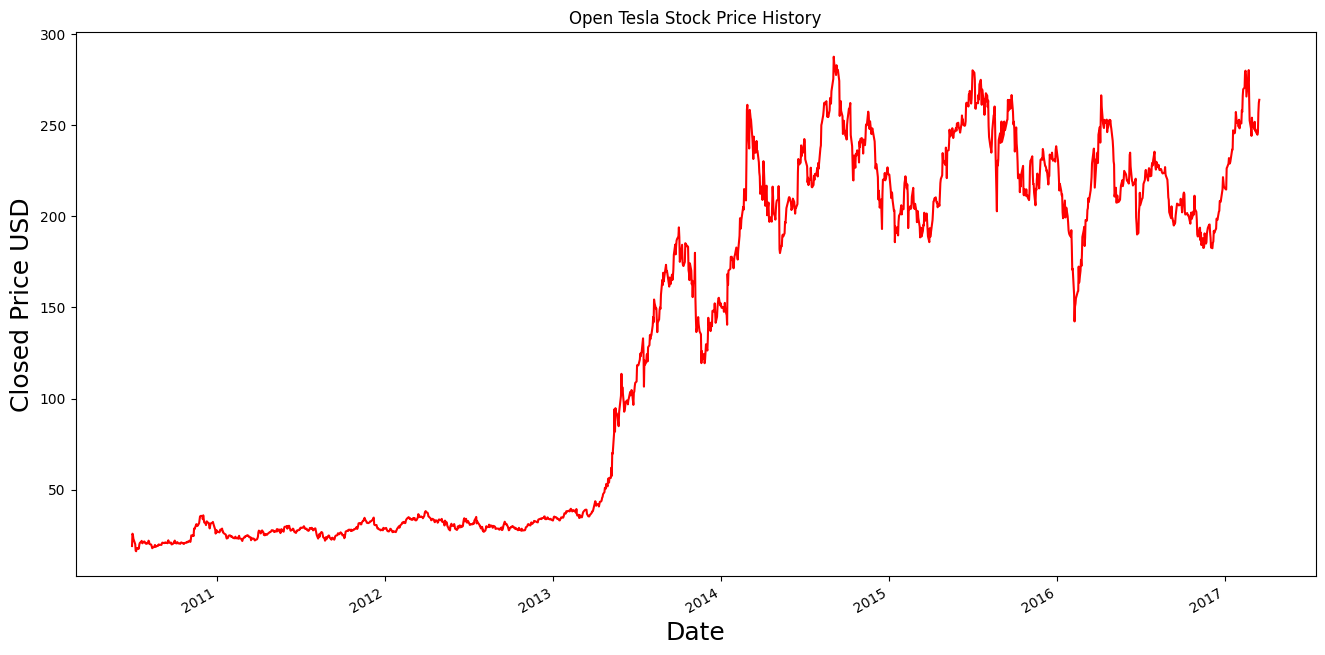

In [22]:
df["Open"].plot(figsize=(16,8),color='red')
plt.title("Open Tesla Stock Price History")
plt.xlabel(('Date'),fontsize=18)
plt.ylabel('Closed Price USD',fontsize=18)

[ 16.139999  16.4       17.389999 ... 282.98999  284.01001  287.670013] This is the Sorted Data of Open Share Price


Text(0, 0.5, 'Frequency')

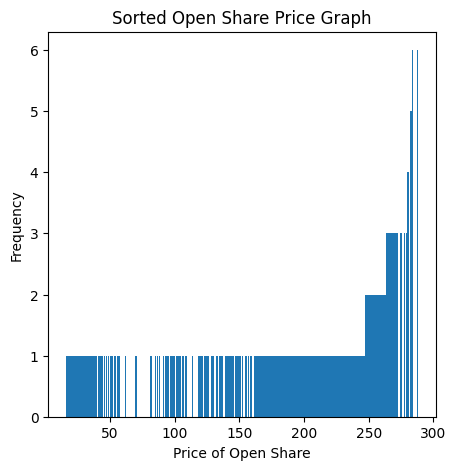

In [23]:
print(np.sort(df['Open']),"This is the Sorted Data of Open Share Price")
plt.figure(figsize=(5,5))
plt.bar(list(np.sort(df['Open'].value_counts().keys())),
        list(np.sort(df['Open'].value_counts())))
plt.title("Sorted Open Share Price Graph")
plt.xlabel("Price of Open Share")
plt.ylabel("Frequency")


[ 16.139999  16.4       17.389999 ... 282.98999  284.01001  287.670013]


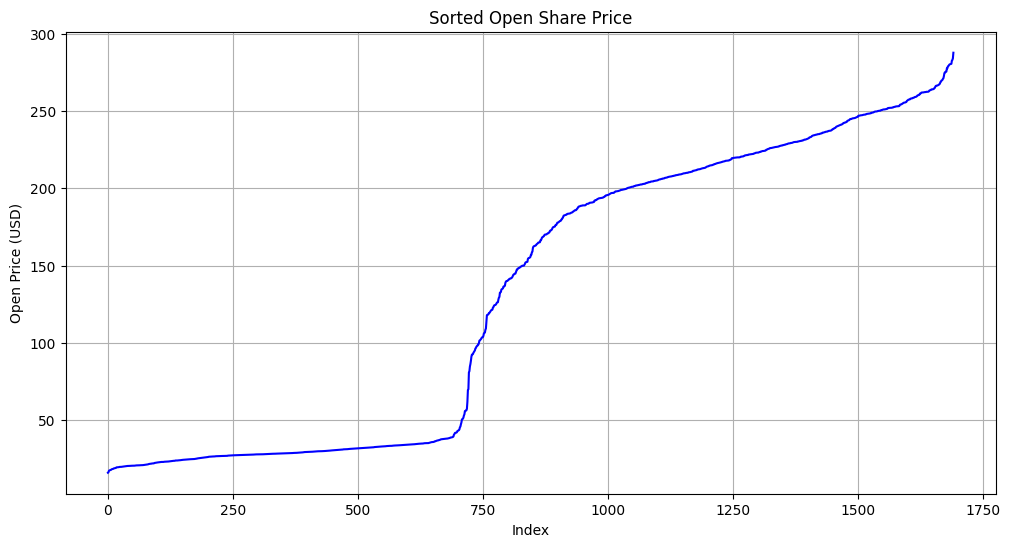

In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Sort the Open prices
sorted_open = np.sort(df["Open"])

print(sorted_open)

# Create the figure
plt.figure(figsize=(12,6))

# Plot the sorted values
plt.plot(sorted_open, color="blue")

# Add title and labels
plt.title("Sorted Open Share Price")
plt.xlabel("Index")
plt.ylabel("Open Price (USD)")

plt.grid(True)
plt.show()

Data Preprocessing

In [25]:
df.isna().any()

,0
Open,False
High,False
Low,False
Close,False
Volume,False
Adj Close,False


Choosing Prediction Column

In [26]:
dataset=df["Open"]
dataset=pd.DataFrame(dataset)
data=dataset.values
data.shape


(1692, 1)

Normalizing Data

In [54]:
scaler=MinMaxScaler(feature_range=(0,1))
scaled_data=scaler.fit_transform(data)

**Spiltting** The Data

In [28]:
# 75% to train, 25% to test
train_size=int(len(data)*.75)
test_size=len(data)-train_size

print("Train Size :",train_size,"Test Size :",test_size)

train_data= scaled_data[ :train_size, 0:1]
test_data= scaled_data[ train_size-60:, 0:1]

Train Size : 1269 Test Size : 423


In [29]:
train_data.shape,test_data.shape

((1269, 1), (483, 1))

In [30]:
# @title
test = dataset.iloc[train_size:, 0:1].copy()
test['Predictions'] = predictions

plt.figure(figsize=(16,6))
plt.plot(train['Open'], label='Train')
plt.plot(test['Open'], label='Actual')
plt.plot(test['Predictions'], label='Predicted')

plt.title("Stock Price Prediction using LSTM")
plt.xlabel("Date")
plt.ylabel("Open Price")
plt.legend()
plt.show()

NameError: name 'predictions' is not defined

In [31]:
train_data.shape,test_data.shape

((1269, 1), (483, 1))

Creating Training Set

In [32]:
# Creating a Training set with 60 time_steps and 1 on
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

In [33]:
#convert to numpy array
x_train, y_train = np.array(x_train), np.array(y_train)

In [34]:
# Reshaping the input
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

In [35]:
x_train.shape,y_train.shape

((1209, 60, 1), (1209,))

Building LSTM Model

In [36]:
model=Sequential()
model.add(LSTM(50,return_sequences=True,input_shape=(x_train.shape[1],1)))
model.add(LSTM(64,return_sequences=False))
model.add(Dense(32))
model.add(Dense(16))
model.add(Dense(1))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [37]:
model.compile(optimizer='adam',loss='mse',metrics=['mean_squared_error'])

In [38]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        29,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,465 (165.88 KB)

 Trainable params: 42,465 (165.88 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
# Fitting the LSTM to the training Set
callbacks= [EarlyStopping(monitor='loss',patience=10,restore_best_weights=True)]
history=model.fit(x_train,y_train,epochs=100,batch_size=32,callbacks=callbacks)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 10s 141ms/step - loss: 0.0185 - mean_squared_error: 0.0185
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - loss: 0.0012 - mean_squared_error: 0.0012
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - loss: 0.0012 - mean_squared_error: 0.0012
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - loss: 0.0011 - mean_squared_error: 0.0011
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - loss: 0.0010 - mean_squared_error: 0.0010
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 61ms/step - loss: 9.8922e-04 - mean_squared_error: 9.8922e-04
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - loss: 9.1608e-04 - mean_squared_error: 9.1608e-04
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - loss: 8.9256e-04 - mean_squared_error: 8.9256e-04
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - loss: 8.6980e-04 - mean_squared_error: 8.6980e-04
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 74ms/step - loss: 8.5594e-04 - mean_squared_error: 8.5594e-

Visulizing **Performance**

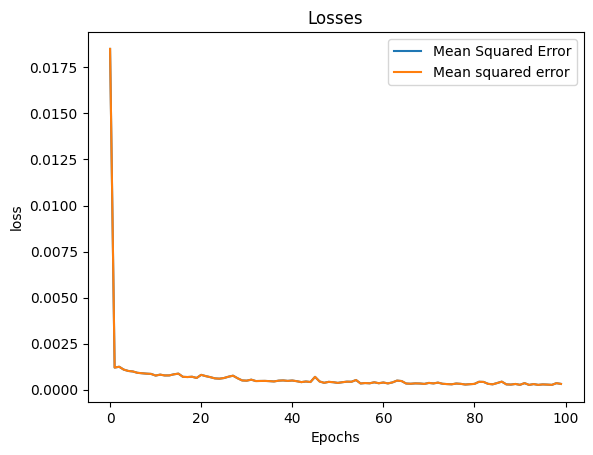

In [40]:
plt.plot(history.history['loss'])
plt.plot(history.history["mean_squared_error"])
plt.legend(["Mean Squared Error",'Mean squared error'])
plt.title("Losses")
plt.xlabel("Epochs")
plt.ylabel("loss")
plt.show ()

Creating Testing Set

In [41]:
# Creating a testig set with 60 time-steps and 1 output
x_test = []
y_test = []

for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])
    y_test.append(test_data[i,0])

x_test, y_test = np.array(x_test), np.array(y_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

In [42]:
x_test.shape,y_test.shape

((423, 60, 1), (423,))

Predicting Testing Data

In [43]:
# inverse y_test scaling
predictions=model.predict(x_test)

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step


In [44]:
#inverse predictions scaling
predictions=scaler.inverse_transform(predictions)
predictions.shape

(423, 1)

Root Mean Square Error

In [45]:
#inverse y_test scaling
y_test=scaler.inverse_transform([y_test])

RMSE=np.sqrt(np.mean(y_test-predictions)**2).round(2)
RMSE

np.float64(1.7)

Visulazing Predictions with the Data

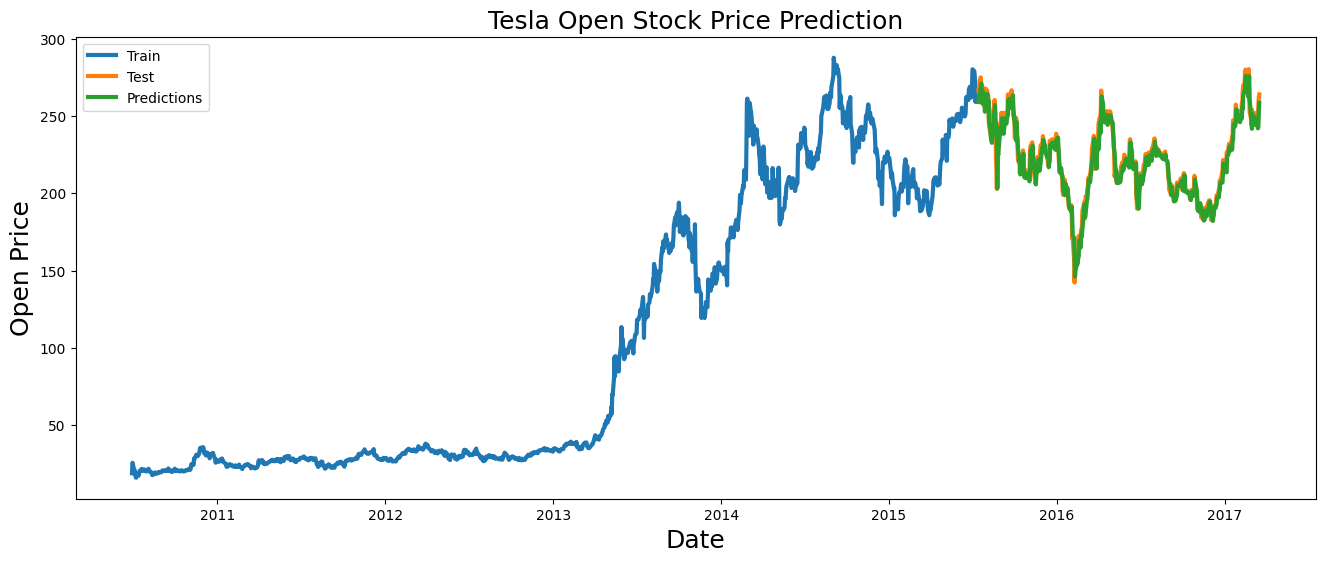

In [46]:
from matplotlib import legend
train=dataset.iloc[:train_size,0:1]
test=dataset.iloc[train_size:,0:1]
test['Predictions'] = predictions

plt.figure(figsize=(16,6))
plt.title('Tesla Open Stock Price Prediction',fontsize=18)
plt.xlabel('Date',fontsize=18)
plt.ylabel('Open Price',fontsize=18)
plt.plot(train['Open'],linewidth=3)
plt.plot(test["Open"],linewidth=3)
plt.plot(test["Predictions"],linewidth=3)
plt.legend(['Train','Test','Predictions'])


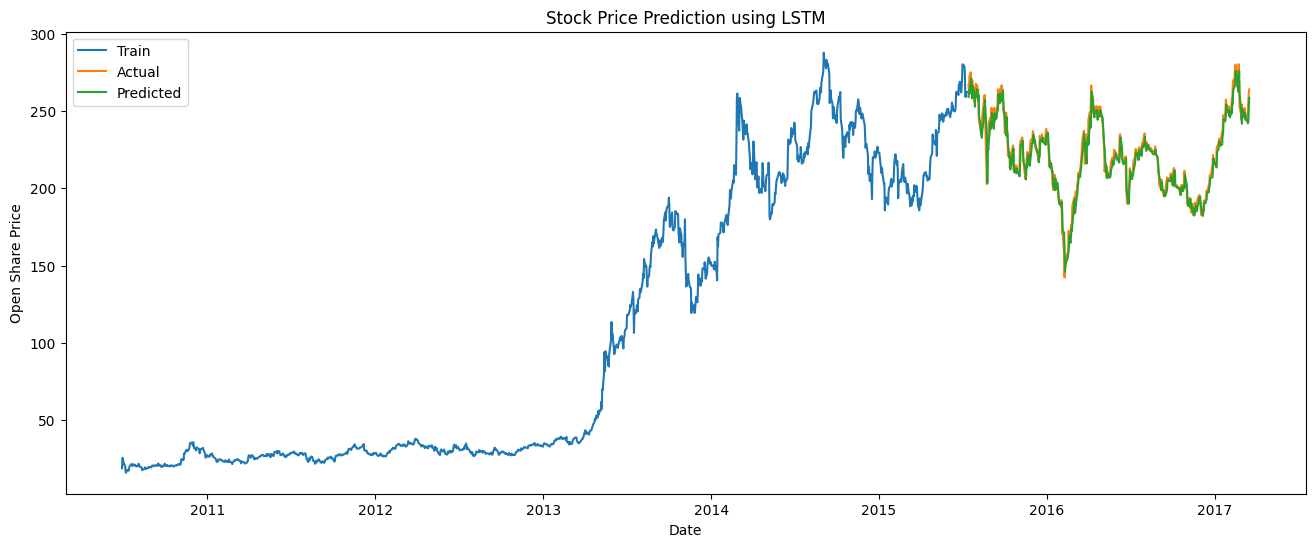

In [47]:
# @title
plt.figure(figsize=(16,6))

plt.plot(train.index, train['Open'], label='Train')
plt.plot(test.index, test['Open'], label='Actual')
plt.plot(test.index, test['Predictions'], label='Predicted')

plt.title("Stock Price Prediction using LSTM")
plt.xlabel("Date")
plt.ylabel("Open Share Price")
plt.legend()

plt.show()

In [55]:
model.save("tesla_stock_models.keras")

In [49]:
from tensorflow.keras.models import load_model

In [50]:
load_model("tesla_stock_models.keras")

<Sequential name=sequential_1, built=True>